In [7]:
import numpy as np
import pandas as pd

def generate_agri_synthetic(
    n_samples: int = 10000,
    seed: int = 42,
    return_latent=False
) -> pd.DataFrame:
    """
    Generate synthetic agricultural dataset with known causal relationships
    and ground-truth feature importance.

    Columns:
        soil_quality, rainfall, temperature, plant_density,
        nitrogen, irrigation,
        ndvi_midseason, canopy_greenness,
        yield, yield_class
    """
    rng = np.random.default_rng(seed)

    # Root variables
    soil_quality = rng.normal(0, 1, size=n_samples)    # S
    rainfall = rng.normal(0, 1, size=n_samples)        # R
    temperature = rng.normal(0, 1, size=n_samples)     # T
    plant_density = rng.normal(0, 1, size=n_samples)   # D

    # Mediators
    eps_N = rng.normal(0, 0.5, size=n_samples)
    nitrogen = 0.7 * soil_quality + 0.3 * rainfall + eps_N

    eps_I = rng.normal(0, 0.5, size=n_samples)
    irrigation = 0.8 * rainfall + 0.2 * soil_quality + eps_I

    # Yield
    T_hot = np.maximum(temperature, 0.0)
    eps_Y = rng.normal(0, 1.0, size=n_samples)
    y_raw = (
        0.4 * nitrogen +
        0.3 * irrigation +
        0.25 * soil_quality +
        0.15 * rainfall +
        0.10 * plant_density -
        0.30 * T_hot +
        eps_Y
    )
    yield_val = 5.0 + y_raw  # shift to be mostly positive

    # Proxies (children of Yield + Soil)
    eps_ndvi = rng.normal(0, 0.3, size=n_samples)
    ndvi_midseason = 0.6 * y_raw + 0.2 * soil_quality + 0.1 * rainfall + eps_ndvi

    eps_green = rng.normal(0, 0.3, size=n_samples)
    canopy_greenness = 0.5 * y_raw + 0.3 * soil_quality + eps_green

    # Binary yield class
    median_yield = np.median(yield_val)
    yield_class = (yield_val >= median_yield).astype(int)

    data = {
        "soil_quality": soil_quality,
        "rainfall": rainfall,
        "temperature": temperature,
        "plant_density": plant_density,
        "nitrogen": nitrogen,
        "irrigation": irrigation,
        "ndvi_midseason": ndvi_midseason,
        "canopy_greenness": canopy_greenness,
        "yield": yield_val,
        "yield_class": yield_class,
    }

    df = pd.DataFrame(data)
    return df

if __name__ == "__main__":
    df = generate_agri_synthetic(n_samples=10000, seed=24131)
    print(df.head())
    print("Median yield:", df["yield"].median())
    df.to_csv("../../datasets/syn_yieldarpit.csv", index=False)

   soil_quality  rainfall  temperature  plant_density  nitrogen  irrigation  \
0      0.388261  0.642509     0.234309      -0.258957  0.343245    0.527546   
1     -1.208786 -0.520010     0.933235       1.071219 -0.999134   -0.989681   
2     -1.610515 -0.446585     0.765988      -0.314559 -0.932169   -0.975492   
3     -1.397181 -2.227591    -0.302255      -1.306343 -2.785340   -1.899289   
4      0.155831  0.734716    -0.417677       0.389344  0.294647    0.537414   

   ndvi_midseason  canopy_greenness     yield  yield_class  
0        0.698800          0.595186  5.968276            1  
1       -1.278363         -1.745365  2.765969            0  
2       -1.537856         -2.028755  2.413628            0  
3       -2.296128         -1.529139  1.935514            0  
4        0.591752          0.848257  5.721383            1  
Median yield: 4.873943805265049


[Synthetic] Saved dataset to: datasets/syn_yieldarpit.csv

[Ground-truth causal importances for yield]
  soil_quality    | β=+0.800 | normalized |β|=0.296
  rainfall        | β=+0.500 | normalized |β|=0.185
  temperature     | β=-0.300 | normalized |β|=0.111
  plant_density   | β=+0.200 | normalized |β|=0.074
  nitrogen        | β=+0.400 | normalized |β|=0.148
  irrigation      | β=+0.500 | normalized |β|=0.185

Causal SHAP (paper-faithful) on: datasets/syn_yieldarpit.csv
Using RandomForest (regression)
✓ Model: R2=0.7303, MAE=0.5462

----------------------------------------------------------------
Step 1: Causal discovery (PC)
----------------------------------------------------------------
Running PC on 6 features...
✓ PC completed -> CPDAG
Graph: 6 nodes, 2 edges
✓ Saved 'causal_graph_syn_yieldarpit_reg.png'

----------------------------------------------------------------
Step 2: Causal SHAP
----------------------------------------------------------------

Fitting SEMs & sampling D

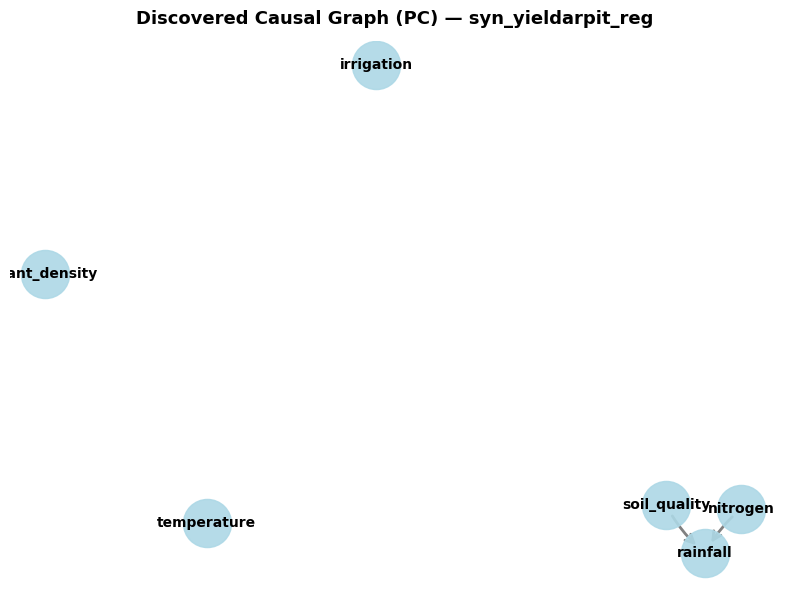

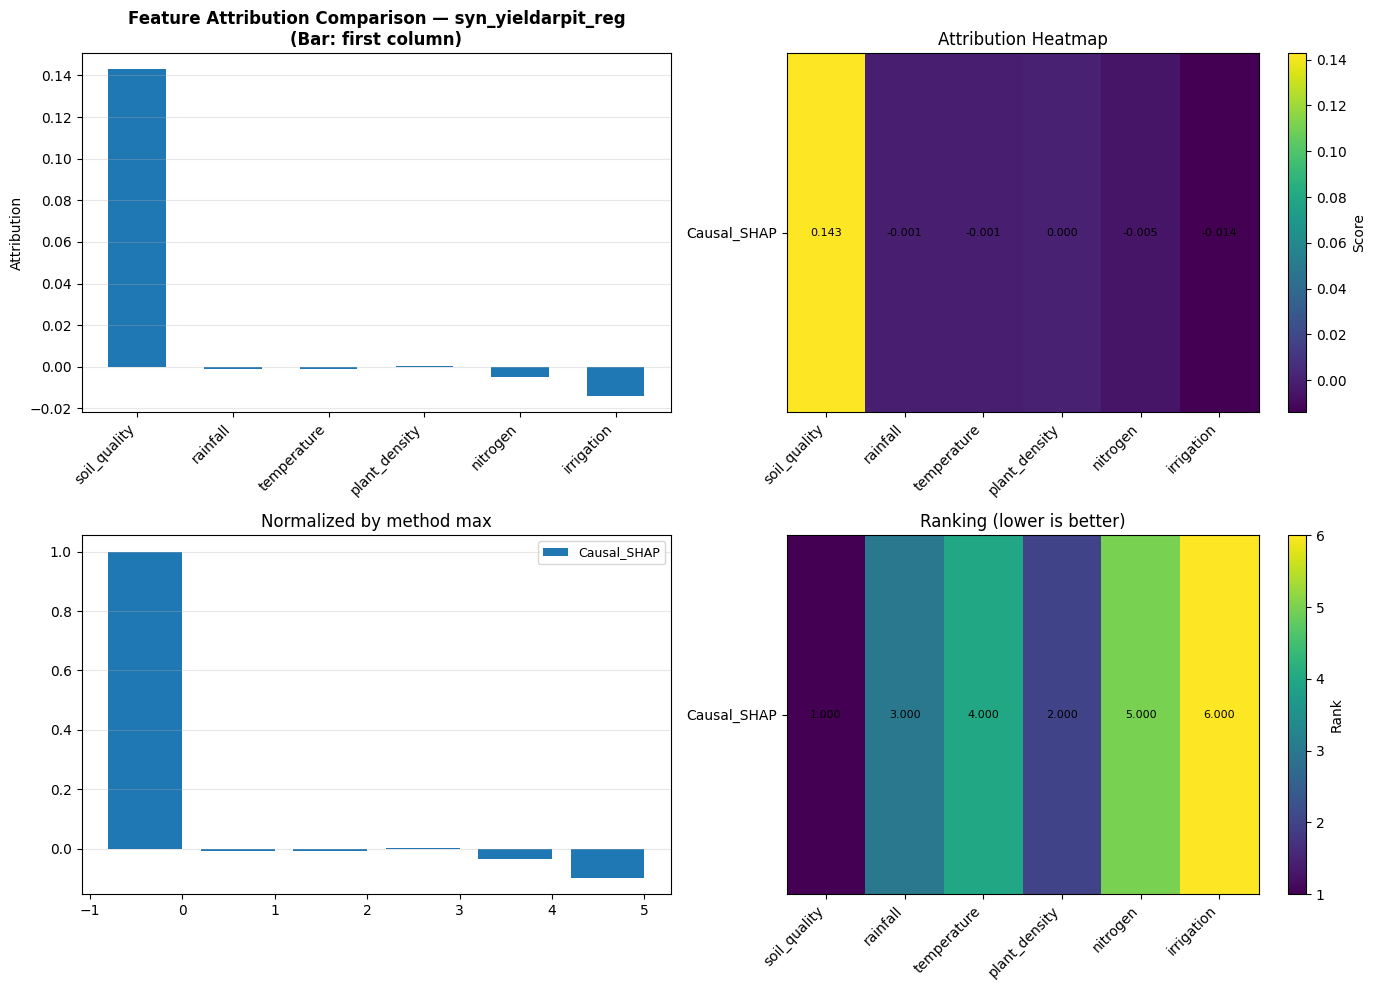

In [8]:
"""
Causal SHAP (paper-faithful) for CSVs with auto regression/classification
- Tested for:
  /mnt/data/cv_risk.csv          (continuous target: cv_risk)
  /mnt/data/lung_cancer_risk.csv (continuous target: lung_cancer_risk)
"""

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from typing import Dict, List, Set, Optional
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import f1_score, accuracy_score, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.utils.multiclass import type_of_target
import networkx as nx

try:
    from xgboost import XGBClassifier, XGBRegressor
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False

HAVE_XGB = False

from causallearn.search.ConstraintBased.PC import pc

CONFIG = {
    'ALPHA_PC': 0.1,
    'MAX_PERM': 200,
    'M_RESAMPLES': 64,
    'GLOBAL_K': 30,
    'RANDOM_SEED': 42,
    'N_DAGS': 5
}
np.random.seed(CONFIG['RANDOM_SEED'])
rng = np.random.default_rng(CONFIG['RANDOM_SEED'])

COMMON_TARGET_NAMES = ["target","label","y","class","outcome",
                       "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
                       "cancer","lung_cancer","has_cancer","diagnosis"]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns: return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map: return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed(df: pd.DataFrame) -> pd.DataFrame:
    return df[[c for c in df.columns if not re.match(r'^unnamed', c, re.I)]].copy()

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

class CausalStructure:
    def __init__(self, alpha=0.05):
        self.alpha = alpha
        self.cpdag = None
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("ok PC completed -> CPDAG")
        return self

    def get_skeleton(self) -> nx.DiGraph:
        G = nx.DiGraph(); G.add_nodes_from(self.feature_names)
        n = len(self.feature_names)
        for i in range(n):
            for j in range(n):
                if i == j: continue
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                elif self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1 and i < j:
                    G.add_edge(self.feature_names[i], self.feature_names[j])
                    G.add_edge(self.feature_names[j], self.feature_names[i])
        return G

    def sample_dags(self, n_samples: int) -> List[nx.DiGraph]:
        dags = []
        names = self.feature_names; n = len(names)
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))
        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            for u, v in undirected:
                if rng.random() < 0.5: G.add_edge(u, v)
                else: G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v); G.add_edge(v, u)
                    else: G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G): break
                    else: G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s)")
        return dags

class LinearMechanisms:
    def __init__(self, dag: nx.DiGraph, feature_names: List[str]):
        self.dag = dag; self.feature_names = feature_names
        self.mechanisms: Dict[str, Dict] = {}; self.topo: List[str] = []

    def fit(self, X: pd.DataFrame):
        try: self.topo = list(nx.topological_sort(self.dag))
        except Exception: self.topo = self._safe_topo()
        for var in self.feature_names:
            parents = list(self.dag.predecessors(var))
            if not parents:
                self.mechanisms[var] = {"parents": [], "intercept": float(X[var].mean()),
                                        "coef": None, "sigma": float(X[var].std(ddof=0))}
            else:
                lr = LinearRegression().fit(X[parents].values, X[var].values)
                resid = X[var].values - lr.predict(X[parents].values)
                self.mechanisms[var] = {"parents": parents, "intercept": float(lr.intercept_),
                                        "coef": lr.coef_.astype(float), "sigma": float(np.std(resid, ddof=0))}
        return self

    def _safe_topo(self) -> List[str]:
        ordered, remaining = [], set(self.feature_names)
        while remaining:
            ready = [n for n in remaining if all(p in ordered or p not in remaining
                                                 for p in self.dag.predecessors(n))]
            if not ready:
                ready = [min(remaining, key=lambda n: len([p for p in self.dag.predecessors(n) if p in remaining]))]
            for n in ready: ordered.append(n); remaining.remove(n)
        return ordered

    def sample_intervention(self, S: Set[str], x_obs: pd.Series) -> Dict[str, float]:
        x_new: Dict[str, float] = {}
        for var in self.topo:
            if var in S: x_new[var] = float(x_obs[var]); continue
            mech = self.mechanisms[var]
            if not mech["parents"]:
                mu, sigma = mech["intercept"], mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
            else:
                pvals = np.array([x_new.get(p, x_obs[p]) for p in mech["parents"]])
                mu = mech["intercept"] + pvals @ mech["coef"]
                sigma = mech["sigma"]
                x_new[var] = mu if sigma < 1e-8 else float(rng.normal(mu, sigma))
        return x_new

class CausalEffects:
    def __init__(self, dags: List[nx.DiGraph], feature_names: List[str]):
        self.dags = dags
        self.feature_names = feature_names
        self.effects: Dict[str, float] = {}

    def compute_effects(self, X: pd.DataFrame, y: pd.Series) -> Dict[str, float]:
        print("Computing IDA-style total effects W_i ...")
        y_vals = y.values
        totals = {f: [] for f in self.feature_names}

        for dag in self.dags:
            G = dag.copy()
            G.add_node("Y")

            # (A) Edge weights among features
            for u, v in dag.edges():
                parents = [p for p in dag.predecessors(v) if p != u]
                X_reg = np.column_stack([X[parents].values, X[u].values]) if parents else X[[u]].values
                lr = LinearRegression().fit(X_reg, X[v].values)
                w = float(abs(lr.coef_[-1]))
                if w > 1e-12:
                    G.add_edge(u, v, weight=w)

            # (B) Direct edges into Y: Y ~ all features
            paY = list(self.feature_names)
            lrY = LinearRegression().fit(X[paY].values, y_vals)
            for feat, w in zip(paY, np.abs(lrY.coef_)):
                if w > 1e-12:
                    G.add_edge(feat, "Y", weight=float(w))

            # (C) Sum of path products i -> ... -> Y
            for i_feat in self.feature_names:
                total = 0.0
                try:
                    for path in nx.all_simple_paths(G, i_feat, "Y", cutoff=10):
                        prod = 1.0
                        ok = True
                        for a, b in zip(path[:-1], path[1:]):
                            ed = G.get_edge_data(a, b)
                            if not ed or "weight" not in ed:
                                ok = False
                                break
                            prod *= ed["weight"]
                        if ok:
                            total += prod
                except Exception:
                    pass
                totals[i_feat].append(total)

        self.effects = {f: (float(np.mean(vals)) if len(vals) else 0.0) for f, vals in totals.items()}
        print("ok W_i computed")
        return self.effects

    def gamma_weights(self) -> Dict[str, float]:
        absW = {k: abs(v) for k, v in self.effects.items()}
        Z = sum(absW.values()) + 1e-12
        return {k: v / Z for k, v in absW.items()}


class CausalSHAP:
    def __init__(self, model, structure: CausalStructure, X_train: pd.DataFrame, y_train: pd.Series, task: str):
        self.model = model; self.structure = structure
        self.X_train = X_train; self.y_train = y_train
        self.features = list(X_train.columns); self.task = task

        print("\nFitting SEMs & sampling DAGs ...")
        self.dags = self.structure.sample_dags(CONFIG['N_DAGS'])
        self.sems = [LinearMechanisms(d, self.features).fit(X_train) for d in self.dags]

        self.effects = CausalEffects(self.dags, self.features)
        self.effects.compute_effects(X_train, y_train)
        self.gamma = self.effects.gamma_weights()
        self._Ef_cache = None
        print("ok CausalSHAP ready")

    def _predict_scalar(self, X_mat: np.ndarray) -> float:
        if self.task == "classification":
            proba = self.model.predict_proba(X_mat)[0]
            return float(proba[np.argmax(proba)])  # predicted class prob (paper used f(x) scalar)
        else:  # regression
            return float(self.model.predict(X_mat)[0])

    def _Ef(self) -> float:
        if self._Ef_cache is None:
            if self.task == "classification":
                P = self.model.predict_proba(self.X_train.values)
                self._Ef_cache = float(P.max(axis=1).mean())  # mean predicted-class prob
            else:
                preds = self.model.predict(self.X_train.values)
                self._Ef_cache = float(np.mean(preds))
        return self._Ef_cache

    def _vc(self, S: Set[str], x: pd.Series, M: int) -> float:
        total = 0.0
        per = max(1, M // max(1, len(self.sems)))
        for sem in self.sems:
            for _ in range(per):
                x_sample = sem.sample_intervention(S, x)
                X_mat = pd.DataFrame([x_sample], columns=self.features).values
                total += self._predict_scalar(X_mat)
        N = per * max(1, len(self.sems))
        return total / N if N > 0 else 0.0

    def explain_instance(self, x: pd.Series, n_perms: int=None, M: int=None) -> pd.Series:
        if n_perms is None: n_perms = CONFIG['MAX_PERM']
        if M is None: M = CONFIG['M_RESAMPLES']

        fx = self._predict_scalar(pd.DataFrame([x], columns=self.features).values)
        phi = np.zeros(len(self.features), dtype=float)

        for _ in range(n_perms):
            perm = rng.permutation(self.features)
            S: Set[str] = set()
            v_prev = self._vc(S, x, M)
            for feat in perm:
                S_next = S | {feat}
                v_curr = self._vc(S_next, x, M)
                delta = v_curr - v_prev
                phi[self.features.index(feat)] += self.gamma[feat] * delta
                v_prev, S = v_curr, S_next

        phi /= n_perms

        sum_phi_c = float(np.sum(phi))
        if abs(sum_phi_c) > 1e-12:
            Ef = self._Ef()
            phi = phi * ((fx - Ef) / sum_phi_c)
        return pd.Series(phi, index=self.features, name="Causal_SHAP")

    def explain_global(self, X_test: pd.DataFrame, k: int=None) -> pd.Series:
        if k is None: k = CONFIG['GLOBAL_K']
        k = min(k, len(X_test))
        idx = rng.choice(len(X_test), size=k, replace=False)
        print(f"\nComputing global Causal SHAP over {k} instances ...")
        exps = []
        for t, i in enumerate(idx, 1):
            if t % 5 == 0: print(f"  {t}/{k}")
            exps.append(self.explain_instance(X_test.iloc[i], n_perms=max(10, CONFIG['MAX_PERM']//4)))
        return pd.concat(exps, axis=1).mean(axis=1).rename("Causal_SHAP_Global")

def annotate_heatmap(ax, data: pd.DataFrame, title: str, cbar_label: str):
    im = ax.imshow(data.values, aspect='auto')
    ax.set_xticks(np.arange(data.shape[1])); ax.set_xticklabels(data.columns, rotation=45, ha='right')
    ax.set_yticks(np.arange(data.shape[0])); ax.set_yticklabels(data.index)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            ax.text(j, i, f"{data.values[i, j]:.3f}", ha='center', va='center', fontsize=8)
    cbar = plt.colorbar(im, ax=ax); cbar.set_label(cbar_label)
    ax.set_title(title)

def plot_comparison(df: pd.DataFrame, title="Feature Attribution Comparison"):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes[0, 0].bar(np.arange(df.shape[0]), df.iloc[:, 0], width=0.6)
    axes[0, 0].set_title(f'{title}\n(Bar: first column)', fontsize=12, fontweight='bold')
    axes[0, 0].set_xticks(np.arange(df.shape[0])); axes[0, 0].set_xticklabels(df.index, rotation=45, ha='right')
    axes[0, 0].set_ylabel('Attribution'); axes[0, 0].grid(axis='y', alpha=0.3)
    annotate_heatmap(axes[0, 1], df.T, 'Attribution Heatmap', 'Score')
    df_norm = df.div(df.abs().max(axis=0), axis=1)
    for i, col in enumerate(df_norm.columns):
        axes[1, 0].bar(np.arange(df_norm.shape[0]) + (i-0.5)*(0.8/len(df_norm.columns)), df_norm[col],
                       width=0.8/len(df_norm.columns), label=col)
    axes[1, 0].set_title('Normalized by method max'); axes[1, 0].legend(fontsize=9); axes[1, 0].grid(axis='y', alpha=0.3)
    ranks = df.rank(ascending=False)
    annotate_heatmap(axes[1, 1], ranks.T, 'Ranking (lower is better)', 'Rank')
    fig.tight_layout(); return fig

def plot_causal_graph(G: nx.DiGraph, title="Discovered Causal Graph (PC)"):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=CONFIG['RANDOM_SEED'], k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=2, arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()


def generate_synthetic_yield_dataset(
    n_samples: int = 5000,
    noise_yield: float = 0.5,
    noise_proxy: float = 0.2,
    seed: int = 42,
    save_path: Optional[str] = None
) -> pd.DataFrame:
    """
    Synthetic SCM for agricultural yield with known causal structure
    and post-treatment proxies (NDVI, canopy greenness).

    True parents of yield: soil_quality, rainfall, temperature,
                           plant_density, nitrogen, irrigation.
    NDVI and canopy_greenness are children of yield.
    """

    rng_local = np.random.default_rng(seed)

    # Exogenous / root causes
    soil_quality   = rng_local.normal(0, 1, n_samples)
    rainfall       = rng_local.normal(0, 1, n_samples)
    temperature    = rng_local.normal(0, 1, n_samples)
    plant_density  = rng_local.normal(0, 1, n_samples)
    nitrogen       = rng_local.normal(0, 1, n_samples)
    irrigation     = rng_local.normal(0, 1, n_samples)

    # True causal coefficients (ground truth)
    beta = {
        "soil_quality":   0.8,
        "rainfall":       0.5,
        "temperature":   -0.3,
        "plant_density":  0.2,
        "nitrogen":       0.4,
        "irrigation":     0.5,
    }

    # Linear Gaussian yield model (true SCM)
    yield_mean = (
        beta["soil_quality"]   * soil_quality +
        beta["rainfall"]       * rainfall +
        beta["temperature"]    * temperature +
        beta["plant_density"]  * plant_density +
        beta["nitrogen"]       * nitrogen +
        beta["irrigation"]     * irrigation
    )
    yield_noise = rng_local.normal(0, noise_yield, n_samples)
    yield_cont = yield_mean + yield_noise

    # Post-treatment proxies (children of yield)
    ndvi_midseason = yield_cont + rng_local.normal(0, noise_proxy, n_samples)
    canopy_greenness = (
        0.6 * yield_cont +
        0.4 * soil_quality +
        rng_local.normal(0, noise_proxy, n_samples)
    )

    # Binary yield class (for classification experiments)
    # Use median split so classes are balanced
    threshold = np.median(yield_cont)
    yield_class = (yield_cont > threshold).astype(int)

    df = pd.DataFrame({
        "soil_quality":      soil_quality,
        "rainfall":          rainfall,
        "temperature":       temperature,
        "plant_density":     plant_density,
        "nitrogen":          nitrogen,
        "irrigation":        irrigation,
        "ndvi_midseason":    ndvi_midseason,
        "canopy_greenness":  canopy_greenness,
        "yield":             yield_cont,
        "yield_class":       yield_class,
    })

    if save_path is not None:
        df.to_csv(save_path, index=False)
        print(f"[Synthetic] Saved dataset to: {save_path}")

    abs_beta = {k: abs(v) for k, v in beta.items()}
    Z = sum(abs_beta.values())
    print("\n[Ground-truth causal importances for yield]")
    for k, v in abs_beta.items():
        print(f"  {k:15s} | β={beta[k]:+0.3f} | normalized |β|={v / Z:0.3f}")

    return df


def run_causal_shap_on_csv(csv_path: str,dataset_name: Optional[str]=None,target_hint: Optional[str]=None, test_size: float=0.25,feature_subset: Optional[List[str]] = None,):
    print("\n" + "="*72)
    print(f"Causal SHAP (paper-faithful) on: {csv_path}")
    print("="*72)

    try:
        raw = pd.read_csv(csv_path)
    except Exception as e:
        print(f"ERROR reading CSV: {e}"); return

    raw = drop_unnamed(raw)

    if dataset_name is None:
        dataset_name = csv_path.split("/")[-1].split(".")[0]

    tgt_col = detect_target_column(raw, target_hint)
    if tgt_col not in raw.columns:
        print("ERROR: target column not found."); return

    y_raw = raw[tgt_col].copy()
    X_raw = raw.drop(columns=[tgt_col])

    if feature_subset is not None:
        keep = [c for c in feature_subset if c in X_raw.columns]
        missing = [c for c in feature_subset if c not in X_raw.columns]
        if missing:
            print(f"[WARN] Missing requested features (ignored): {missing}")
        X_raw = X_raw[keep]

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan).fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary","multiclass"]:
        task = "classification"
        y_vec = y_raw.astype(int).values
    else:
        task = "regression"
        y_vec = pd.to_numeric(y_raw, errors="coerce").values
        if np.isnan(y_vec).any():
            print("ERROR: target has non-numeric values that cannot be coerced."); return

    strat = y_vec if (task=="classification" and len(np.unique(y_vec))>1) else None
    X_train, X_test, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=CONFIG['RANDOM_SEED'], stratify=strat
    )

    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    Xte = pd.DataFrame(scaler.transform(X_test),  columns=X_test.columns,  index=X_test.index)

    if task=="classification":
        n_classes = int(len(np.unique(y_train)))
        if HAVE_XGB:
            model = XGBClassifier(
                n_estimators=160, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED'], verbosity=0,
                objective="multi:softprob" if n_classes>2 else "binary:logistic",
                num_class=n_classes if n_classes>2 else None
            )
            print("Using XGBoost (classification)")
        else:
            model = RandomForestClassifier(n_estimators=160, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (classification)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred); f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}, classes={n_classes}")
    else:
        if HAVE_XGB:
            model = XGBRegressor(
                n_estimators=200, max_depth=5, learning_rate=0.08,
                subsample=0.9, colsample_bytree=0.9,
                random_state=CONFIG['RANDOM_SEED']
            )
            print("Using XGBoost (regression)")
        else:
            model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=CONFIG['RANDOM_SEED'])
            print("Using RandomForest (regression)")
        model.fit(Xtr.values, y_train)
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred); mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Step 1: PC discovery
    print("\n" + "-"*64)
    print("Step 1: Causal discovery (PC)")
    print("-"*64)
    cs = CausalStructure(alpha=CONFIG['ALPHA_PC']).discover(Xtr)
    G_skel = cs.get_skeleton()
    print(f"Graph: {G_skel.number_of_nodes()} nodes, {G_skel.number_of_edges()} edges")
    fig = plot_causal_graph(G_skel, title=f"Discovered Causal Graph (PC) — {dataset_name}")
    fig.savefig(f'causal_graph_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'causal_graph_{dataset_name}.png'")

    # Step 2: Causal SHAP
    print("\n" + "-"*64)
    print("Step 2: Causal SHAP")
    print("-"*64)
    cshap = CausalSHAP(model, cs, Xtr, pd.Series(y_train), task=task)
    print("\nTotal causal effects W_i and gamma_i:")
    for f in Xtr.columns:
        print(f"  {f:20s}  W={cshap.effects.effects[f]:10.6f}   γ={cshap.gamma[f]:.6f}")

    glob = cshap.explain_global(Xte, k=min(CONFIG['GLOBAL_K'], len(Xte)))

    # Step 3: Save/plot comparison (Causal_SHAP only by default for regression)
    cols = {"Causal_SHAP": glob}
    df = pd.DataFrame(cols)
    df.to_csv(f"attribution_scores_{dataset_name}.csv", index=True)
    print("\n" + "-"*64)
    print("Step 3: Comparison & Save")
    print("-"*64)
    print(df.round(6).to_string())
    print(f"\nSaved: attribution_scores_{dataset_name}.csv")

    fig2 = plot_comparison(df, title=f"Feature Attribution Comparison — {dataset_name}")
    fig2.savefig(f'attribution_comparison_{dataset_name}.png', dpi=150, bbox_inches='tight')
    print(f"Saved 'attribution_comparison_{dataset_name}.png'")

    try: plt.show()
    except Exception: pass

def main():
    # 1) Generate synthetic dataset
    syn_path = "../../datasets/syn_yieldarpit.csv"
    generate_synthetic_yield_dataset(
        n_samples=5000,
        noise_yield=0.5,
        noise_proxy=0.2,
        seed=42,
        save_path=syn_path,
    )

    # 2) Run Causal SHAP on regression task (yield as target)
    true_causes = [
        "soil_quality",
        "rainfall",
        "temperature",
        "plant_density",
        "nitrogen",
        "irrigation",
    ]

    run_causal_shap_on_csv(
        syn_path,
        dataset_name="syn_yieldarpit_reg",
        target_hint="yield",          # use continuous yield
        test_size=0.25,
        feature_subset=true_causes,   # use only true parents of yield
    )


if __name__ == "__main__":
    main()

In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Directory to save the processed datasets
OUT_DIR = "./new_datasets"
os.makedirs(OUT_DIR, exist_ok=True)
RANDOM_STATE = 42

def process_and_save_dataset(dataset_name, openml_name, openml_version, target_column):
    print(f"\n[{dataset_name}] Fetching dataset from OpenML...")

    # 1. Fetch Dataset
    try:
        data = fetch_openml(name=openml_name, version=openml_version, as_frame=True, parser='auto')
        df = data.frame
    except Exception as e:
        print(f"Failed to fetch {dataset_name}: {e}")
        return

    # Drop rows where target is missing
    df = df.dropna(subset=[target_column])

    X = df.drop(columns=[target_column])
    y_raw = df[target_column]

    # 2. Identify Column Types
    numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

    print(f"[{dataset_name}] Found {len(numeric_features)} numeric and {len(categorical_features)} categorical features.")

    # 3. Build Preprocessing Pipelines
    # Numeric: Impute missing with median -> Standard Scale
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    # Categorical: Impute missing with 'missing' -> One-Hot Encode
    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features)
        ])

    # 4. Transform X and Encode y
    print(f"[{dataset_name}] Applying transformations...")
    X_processed = preprocessor.fit_transform(X)

    # Get the newly generated feature names (after one-hot encoding)
    feature_names = preprocessor.get_feature_names_out()
    # Clean up sklearn's prefixing (e.g., 'num__age' -> 'age')
    feature_names = [name.split('__')[-1] for name in feature_names]

    # Encode labels to 0 and 1
    le = LabelEncoder()
    y_processed = le.fit_transform(y_raw)

    print(f"[{dataset_name}] Target classes mapped: {dict(zip(le.classes_, le.transform(le.classes_)))}")

    # 5. Train / Test Split
    X_train, X_test, y_train, y_test = train_test_split(
        X_processed, y_processed, test_size=0.2, random_state=RANDOM_STATE, stratify=y_processed
    )

    # 6. Save as NPZ
    out_path = os.path.join(OUT_DIR, f"{dataset_name}_preprocessed.npz")
    np.savez_compressed(
        out_path,
        X_train=X_train,
        X_test=X_test,
        y_train=y_train,
        y_test=y_test,
        feature_names=np.array(feature_names, dtype=str)
    )
    print(f"[{dataset_name}] Successfully saved to {out_path} with shape {X_train.shape}")


if __name__ == "__main__":
    # Define the benchmark datasets to fetch
    datasets_to_process = [
        ("adult", "adult", 2, "class"),
        ("german_credit", "credit-g", 1, "class"),
        ("heloc", "heloc", 1, "RiskPerformance"),
        # COMPAS requires a specific version on OpenML
        ("compas", "compas-two-years", 1, "two_year_recid")
    ]

    for name, oml_name, oml_version, target in datasets_to_process:
        process_and_save_dataset(name, oml_name, oml_version, target)

    print("\nAll datasets processed and ready for XAI evaluation!")


[adult] Fetching dataset from OpenML...
[adult] Found 6 numeric and 8 categorical features.
[adult] Applying transformations...
[adult] Target classes mapped: {'<=50K': np.int64(0), '>50K': np.int64(1)}
[adult] Successfully saved to ./new_datasets/adult_preprocessed.npz with shape (39073, 108)

[german_credit] Fetching dataset from OpenML...
[german_credit] Found 7 numeric and 13 categorical features.
[german_credit] Applying transformations...
[german_credit] Target classes mapped: {'bad': np.int64(0), 'good': np.int64(1)}
[german_credit] Successfully saved to ./new_datasets/german_credit_preprocessed.npz with shape (800, 61)

[heloc] Fetching dataset from OpenML...
[heloc] Found 22 numeric and 0 categorical features.
[heloc] Applying transformations...
[heloc] Target classes mapped: {'0': np.int64(0), '1': np.int64(1)}
[heloc] Successfully saved to ./new_datasets/heloc_preprocessed.npz with shape (8000, 22)

[compas] Fetching dataset from OpenML...
Failed to fetch compas: Dataset co

In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

OUT_DIR = "./new_datasets"
os.makedirs(OUT_DIR, exist_ok=True)
RANDOM_STATE = 42

def process_compas():
    dataset_name = "compas"
    target_column = "two_year_recid"
    data_id = 42192  # The exact OpenML ID for compas-two-years

    print(f"\n[{dataset_name}] Fetching dataset from OpenML (ID: {data_id})...")

    try:
        # Fetch directly by ID to avoid name/version mismatch
        data = fetch_openml(data_id=data_id, as_frame=True, parser='auto')
        df = data.frame
    except Exception as e:
        print(f"Failed to fetch {dataset_name}: {e}")
        return

    # Drop rows where target is missing
    df = df.dropna(subset=[target_column])

    X = df.drop(columns=[target_column])
    y_raw = df[target_column]

    numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

    print(f"[{dataset_name}] Found {len(numeric_features)} numeric and {len(categorical_features)} categorical features.")

    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features)
        ])

    print(f"[{dataset_name}] Applying transformations...")
    X_processed = preprocessor.fit_transform(X)

    feature_names = preprocessor.get_feature_names_out()
    feature_names = [name.split('__')[-1] for name in feature_names]

    le = LabelEncoder()
    y_processed = le.fit_transform(y_raw)

    print(f"[{dataset_name}] Target classes mapped: {dict(zip(le.classes_, le.transform(le.classes_)))}")

    X_train, X_test, y_train, y_test = train_test_split(
        X_processed, y_processed, test_size=0.2, random_state=RANDOM_STATE, stratify=y_processed
    )

    out_path = os.path.join(OUT_DIR, f"{dataset_name}_preprocessed.npz")
    np.savez_compressed(
        out_path,
        X_train=X_train,
        X_test=X_test,
        y_train=y_train,
        y_test=y_test,
        feature_names=np.array(feature_names, dtype=str)
    )
    print(f"[{dataset_name}] Successfully saved to {out_path} with shape {X_train.shape}")

if __name__ == "__main__":
    process_compas()


[compas] Fetching dataset from OpenML (ID: 42192)...
[compas] Found 7 numeric and 6 categorical features.
[compas] Applying transformations...
[compas] Target classes mapped: {'0': np.int64(0), '1': np.int64(1)}
[compas] Successfully saved to ./new_datasets/compas_preprocessed.npz with shape (4222, 19)


In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

OUT_DIR = "./new_datasets"
os.makedirs(OUT_DIR, exist_ok=True)
RANDOM_STATE = 42

def process_diabetes():
    dataset_name = "pima_diabetes"
    target_column = "class"
    data_id = 37  # Exact OpenML ID for Pima-Indians Diabetes

    print(f"\n[{dataset_name}] Fetching dataset from OpenML (ID: {data_id})...")

    try:
        data = fetch_openml(data_id=data_id, as_frame=True, parser='auto')
        df = data.frame
    except Exception as e:
        print(f"Failed to fetch {dataset_name}: {e}")
        return

    # Drop rows where target is missing
    df = df.dropna(subset=[target_column])

    X = df.drop(columns=[target_column])
    y_raw = df[target_column]

    print(f"[{dataset_name}] Found {X.shape[1]} features (All numeric).")

    # Pipeline: Impute missing values with median, then scale
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    print(f"[{dataset_name}] Applying transformations...")
    X_processed = numeric_transformer.fit_transform(X)
    feature_names = X.columns.tolist()

    # Encode target (usually 'tested_negative' / 'tested_positive' -> 0 / 1)
    le = LabelEncoder()
    y_processed = le.fit_transform(y_raw)

    print(f"[{dataset_name}] Target classes mapped: {dict(zip(le.classes_, le.transform(le.classes_)))}")

    # Split
    X_train, X_test, y_train, y_test = train_test_split(
        X_processed, y_processed, test_size=0.2, random_state=RANDOM_STATE, stratify=y_processed
    )

    out_path = os.path.join(OUT_DIR, f"{dataset_name}_preprocessed.npz")
    np.savez_compressed(
        out_path,
        X_train=X_train,
        X_test=X_test,
        y_train=y_train,
        y_test=y_test,
        feature_names=np.array(feature_names, dtype=str)
    )
    print(f"[{dataset_name}] Successfully saved to {out_path} with shape {X_train.shape}")

if __name__ == "__main__":
    process_diabetes()


[pima_diabetes] Fetching dataset from OpenML (ID: 37)...
[pima_diabetes] Found 8 features (All numeric).
[pima_diabetes] Applying transformations...
[pima_diabetes] Target classes mapped: {'tested_negative': np.int64(0), 'tested_positive': np.int64(1)}
[pima_diabetes] Successfully saved to ./new_datasets/pima_diabetes_preprocessed.npz with shape (614, 8)


In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

OUT_DIR = "./new_datasets"
os.makedirs(OUT_DIR, exist_ok=True)
RANDOM_STATE = 42

def process_gmsc():
    dataset_name = "give_me_some_credit"
    data_id = 45577  # OpenML ID for Give Me Some Credit

    print(f"\n[{dataset_name}] Fetching dataset from OpenML (ID: {data_id})...")

    try:
        data = fetch_openml(data_id=data_id, as_frame=True, parser='auto')
        df = data.frame
    except Exception as e:
        print(f"Failed to fetch {dataset_name}: {e}")
        return

    # Determine the target column (usually 'SeriousDlqin2yrs' or 'class')
    target_column = "SeriousDlqin2yrs" if "SeriousDlqin2yrs" in df.columns else "class"

    # Drop rows where target is missing
    df = df.dropna(subset=[target_column])

    X = df.drop(columns=[target_column])
    y_raw = df[target_column]

    numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

    print(f"[{dataset_name}] Found {len(numeric_features)} numeric and {len(categorical_features)} categorical features.")

    # Impute missing values with median, then scale
    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numeric_transformer, numeric_features),
            ('cat', categorical_transformer, categorical_features)
        ])

    print(f"[{dataset_name}] Applying transformations...")
    X_processed = preprocessor.fit_transform(X)

    feature_names = preprocessor.get_feature_names_out()
    feature_names = [name.split('__')[-1] for name in feature_names]

    le = LabelEncoder()
    y_processed = le.fit_transform(y_raw)

    print(f"[{dataset_name}] Target classes mapped: {dict(zip(le.classes_, le.transform(le.classes_)))}")

    X_train, X_test, y_train, y_test = train_test_split(
        X_processed, y_processed, test_size=0.2, random_state=RANDOM_STATE, stratify=y_processed
    )

    out_path = os.path.join(OUT_DIR, f"{dataset_name}_preprocessed.npz")
    np.savez_compressed(
        out_path,
        X_train=X_train,
        X_test=X_test,
        y_train=y_train,
        y_test=y_test,
        feature_names=np.array(feature_names, dtype=str)
    )
    print(f"[{dataset_name}] Successfully saved to {out_path} with shape {X_train.shape}")

if __name__ == "__main__":
    process_gmsc()


[give_me_some_credit] Fetching dataset from OpenML (ID: 45577)...
[give_me_some_credit] Found 10 numeric and 0 categorical features.
[give_me_some_credit] Applying transformations...
[give_me_some_credit] Target classes mapped: {'0': np.int64(0), '1': np.int64(1)}
[give_me_some_credit] Successfully saved to ./new_datasets/give_me_some_credit_preprocessed.npz with shape (120000, 10)
